In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_predict
from sklearn import metrics

from sklearn.naive_bayes import CategoricalNB
import numpy as np

import os
import os.path
from pathlib import Path
import glob
import random
from PIL import Image
import shutil

!pip install tensorflow
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

Author: Vamshi Avvari

The goal of this project is to use the following data set of 6862 images of different types of weather "Weather Image Recognition" (https://www.kaggle.com/datasets/jehanbhathena/weather-dataset/data), to build models and implement different machine learning methods to develop a system for weather classification such that any given weather image can be accurately classified as the correct weather type or condition. 

The dataset contains different weather types for the 6862 included images, and are listed below the following code after sorting classes - 


In [2]:

data_dir = r"C:\Users\vamsh\Anaconda\dataset"   # folder that directly contains the class subfolders

# sorting class folders alphabetically
weather_types = sorted(
    d for d in os.listdir(data_dir)
    if os.path.isdir(os.path.join(data_dir, d))
)
print(weather_types) # checking sorting

# getting image paths and labels for images
weather_paths = []
weather_labels = []
for weather_type in weather_types:
    for ext in ("jpg", "jpeg", "png"):
        folder_path = os.path.join(data_dir, weather_type, f"*.{ext}")
        found = glob.glob(folder_path, recursive=True)
        weather_paths.extend(found)
        weather_labels.extend([weather_type] * len(found))   # label = folder name

weather_df = pd.DataFrame({'image_path': weather_paths, 'weather_label': weather_labels})

['dew', 'fogsmog', 'frost', 'glaze', 'hail', 'lightning', 'rain', 'rainbow', 'rime', 'sandstorm', 'snow']


***Preprocessing and Exploratory Data Analysis***

Total images: 6862
0 = dew (698 images)
1 = fogsmog (851 images)
2 = frost (475 images)
3 = glaze (639 images)
4 = hail (591 images)
5 = lightning (377 images)
6 = rain (526 images)
7 = rainbow (232 images)
8 = rime (1160 images)
9 = sandstorm (692 images)
10 = snow (621 images)


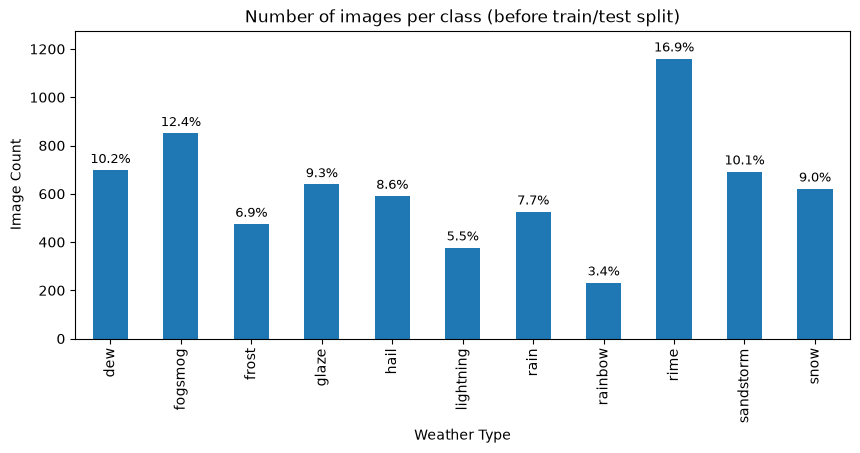

In [3]:
print("Total images:", len(weather_df))

class_counts = weather_df['weather_label'].value_counts().sort_index()
class_names = sorted(weather_df['weather_label'].unique())
total = class_counts.sum()

# printing each class along with their integer labels
for i, (name, count) in enumerate(class_counts.items()):
    print(i, "=", name, f"({count} images)")

# bar chart to give us a feel for the image distribution
fig, ax = plt.subplots(figsize=(10, 4))
class_counts.plot(kind='bar', ax=ax)          
ax.set_title("Number of images per class (before train/test split)")
ax.set_xlabel("Weather Type")
ax.set_ylabel("Image Count")
ax.tick_params(axis='x', rotation=90)       

# adding percentage label above each bar
for bar in ax.patches:
    height = bar.get_height()
    pct = height / total * 100
    ax.annotate(f"{pct:.1f}%",
                (bar.get_x() + bar.get_width() / 2, height),
                ha='center', va='bottom', fontsize=9,
                xytext=(0, 3), textcoords='offset points')

ax.set_ylim(0, class_counts.max() * 1.1)      # extra space
plt.show()

We can also display random images from each class to get a better sense of each weather type -

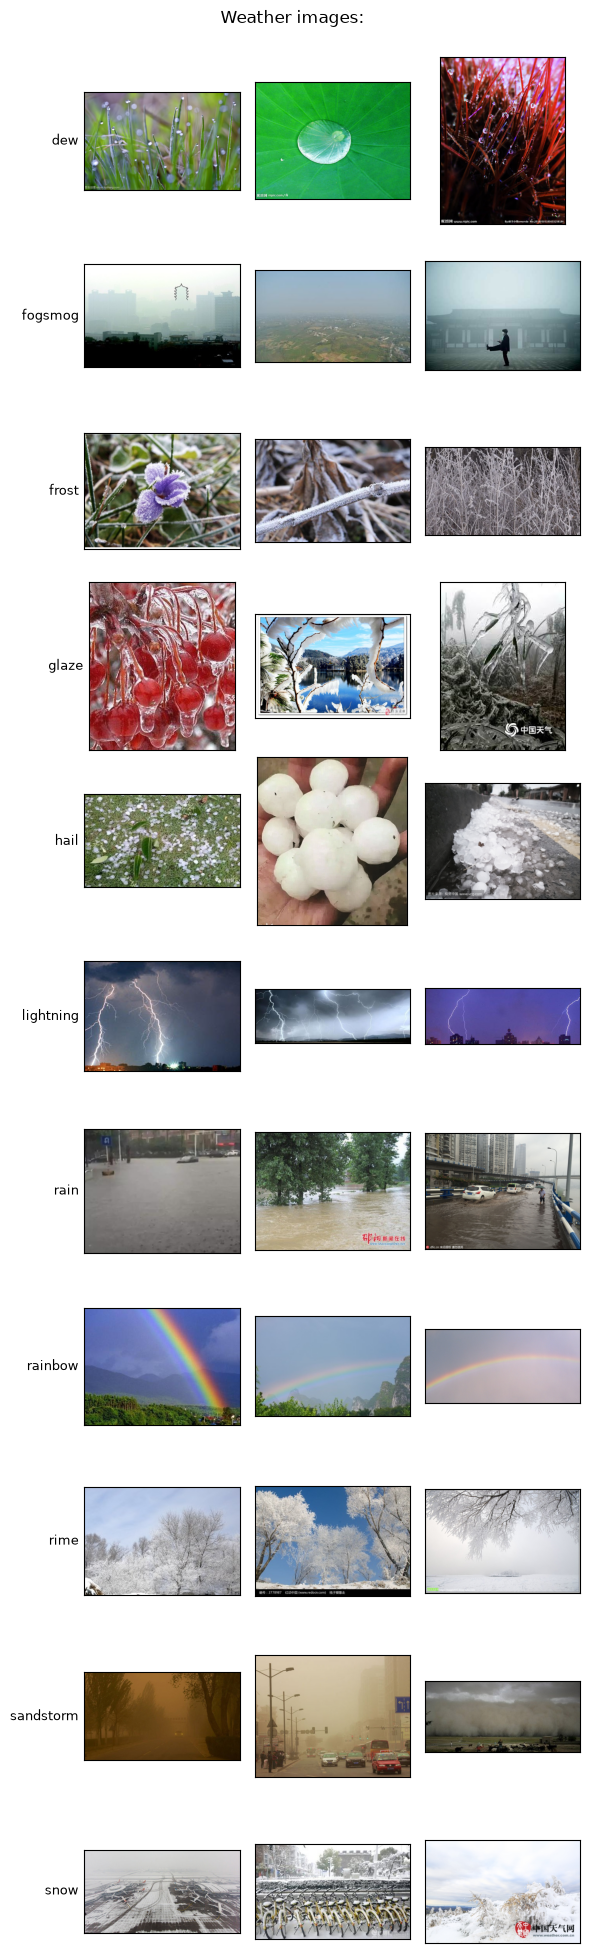

In [4]:
from PIL import Image

n_per_class = 3
n_classes = len(class_names)

fig, axes = plt.subplots(n_classes, n_per_class, figsize=(n_per_class * 2, n_classes * 1.8))

for row, name in enumerate(class_names):
    # using .sample() function to get random iamges
    sample = weather_df[weather_df['weather_label'] == name].sample(n_per_class, random_state=None)

    for col, path in enumerate(sample['image_path']):
        ax = axes[row, col]
        ax.imshow(Image.open(path).convert("RGB"))
        ax.set_xticks([])
        ax.set_yticks([])
        if col == 0:
            ax.set_ylabel(name, rotation=0, ha='right', va='center', fontsize=9)

plt.suptitle("Weather images: ", y=1.0)
plt.tight_layout()
plt.show()

Now that we have a better understanding of our data after some initial exploration, we need to split our data into test and training sets to prepare for later methods - 

In [5]:
# building 70% training and 30% test dataframes
train_weather_df, test_weather_df = train_test_split(
    weather_df,
    test_size=0.3,
    stratify=weather_df['weather_label'],
    random_state=42,
)
train_weather_df = train_weather_df.reset_index(drop=True)
test_weather_df = test_weather_df.reset_index(drop=True)

# outputting new train and test dataframes
print('Sample Training Data:')
display(train_weather_df.sample(frac=1, random_state=42).head(5))

print('Sample Test Data:')
display(test_weather_df.sample(frac=1, random_state=42).head(5))

# double checking size and proportion balance just in case
print("Train Size: " + str(len(train_weather_df)))
print("Test Size: " + str(len(test_weather_df)))

Sample Training Data:


,image_path,weather_label
596,C:\Users\vamsh\Anaconda\dataset\snow\1447.jpg,snow
3372,C:\Users\vamsh\Anaconda\dataset\sandstorm\3425...,sandstorm
2702,C:\Users\vamsh\Anaconda\dataset\fogsmog\4691.jpg,fogsmog
2473,C:\Users\vamsh\Anaconda\dataset\hail\0263.jpg,hail
8,C:\Users\vamsh\Anaconda\dataset\rime\5747.jpg,rime


Sample Test Data:


,image_path,weather_label
1298,C:\Users\vamsh\Anaconda\dataset\rainbow\0696.jpg,rainbow
591,C:\Users\vamsh\Anaconda\dataset\glaze\6558.jpg,glaze
1318,C:\Users\vamsh\Anaconda\dataset\sandstorm\3203...,sandstorm
1067,C:\Users\vamsh\Anaconda\dataset\rime\5264.jpg,rime
29,C:\Users\vamsh\Anaconda\dataset\dew\2414.jpg,dew


Train Size: 4803
Test Size: 2059


***K-Means Clustering***

Before we can group our images into clusters, since the sizes of our weather images vary, we need to resize them to (100,100) and convert them to RGB so they all have the same shape (100,100,3). Then we use label encoder to encode weather labels and store in an encoded dataframe.  

In [6]:
from sklearn.preprocessing import LabelEncoder

IMG_SIZE = (100, 100)   # scaling to (100,100)
def load_images(df):
    imgs, keep = [], []
    for i, p in enumerate(df['image_path']):
        try:
            imgs.append(np.array(Image.open(p).convert("RGB").resize(IMG_SIZE)))
            keep.append(i)
        except Exception:
            print("Can't read image:", p)
    return np.array(imgs, dtype=np.uint8), keep

X_train, keep_tr = load_images(train_weather_df)
X_test, keep_te = load_images(test_weather_df)

# ensuring dataframes and arrays match up
train_weather_df = train_weather_df.iloc[keep_tr].reset_index(drop=True)
test_weather_df = test_weather_df.iloc[keep_te].reset_index(drop=True)

# checking shape of scaled data
y_train = np.array(train_weather_df['weather_label'])
y_test = np.array(test_weather_df['weather_label'])
print("Train:", X_train.shape, "| Test:", X_test.shape)

label_encoder = LabelEncoder()
y_train_encoded = label_encoder.fit_transform(y_train)
y_test_encoded = label_encoder.transform(y_test)

num_classes = len(label_encoder.classes_)
encoded_dict = pd.DataFrame({'train_labels': label_encoder.classes_,
                             'train_encoded_labels': range(num_classes)})
display(encoded_dict) # displaying encoded values

# different color for each type
class_colors = {c: plt.cm.tab20(i) for i, c in enumerate(label_encoder.classes_)}

Train: (4803, 100, 100, 3) | Test: (2059, 100, 100, 3)


,train_labels,train_encoded_labels
0,dew,0
1,fogsmog,1
2,frost,2
3,glaze,3
4,hail,4
5,lightning,5
6,rain,6
7,rainbow,7
8,rime,8
9,sandstorm,9


Now we rescale pixels so we can make clusters of similar pixel values - 

In [7]:
from sklearn.cluster import KMeans

X = X_train.reshape(len(X_train), -1).astype(np.float32) / 255.
print("Array Shape:", X.shape)

n_groups = 22   # k = 22 had best results, double the number of total classes
print("Groups:", n_groups)

# runs 50 times from random centroid
kmeans = KMeans(n_clusters=n_groups, n_init=50, random_state=42)
kmeans.fit(X)
kmeans_labs = kmeans.labels_

Array Shape: (4803, 30000)
Groups: 22


K-Means Centroid Images:



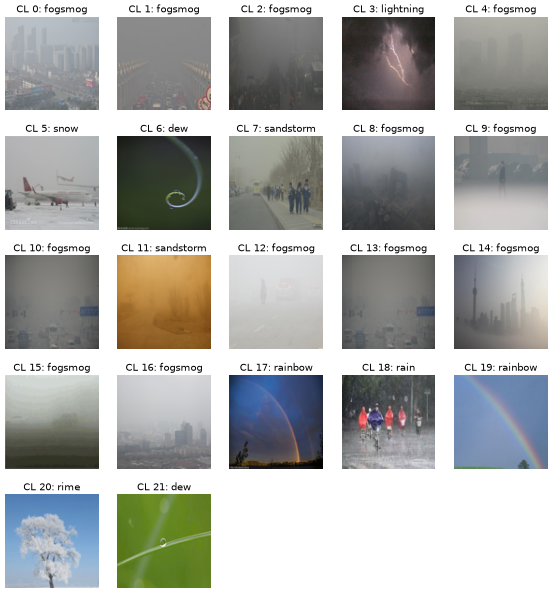

In [8]:
X_distance = kmeans.transform(X) # computing distance from every centroid
rep_index = np.argmin(X_distance, axis=0)     # closest image to each centroid

X_rep = X_train[rep_index]
y_rep = y_train[rep_index]

# displaying representative images for clusters
ncols = 5
nrows = int(np.ceil(n_groups / ncols))
fig, ax = plt.subplots(nrows, ncols, figsize=(14, 3 * nrows), dpi=50)
ax = ax.flatten()
for i in range(len(ax)):
    ax[i].axis('off')
    if i < n_groups:
        ax[i].imshow(X_rep[i])
        ax[i].set_title(f"CL {i}: {y_rep[i]}", fontsize=15)
print("K-Means Centroid Images:\n")
plt.show()

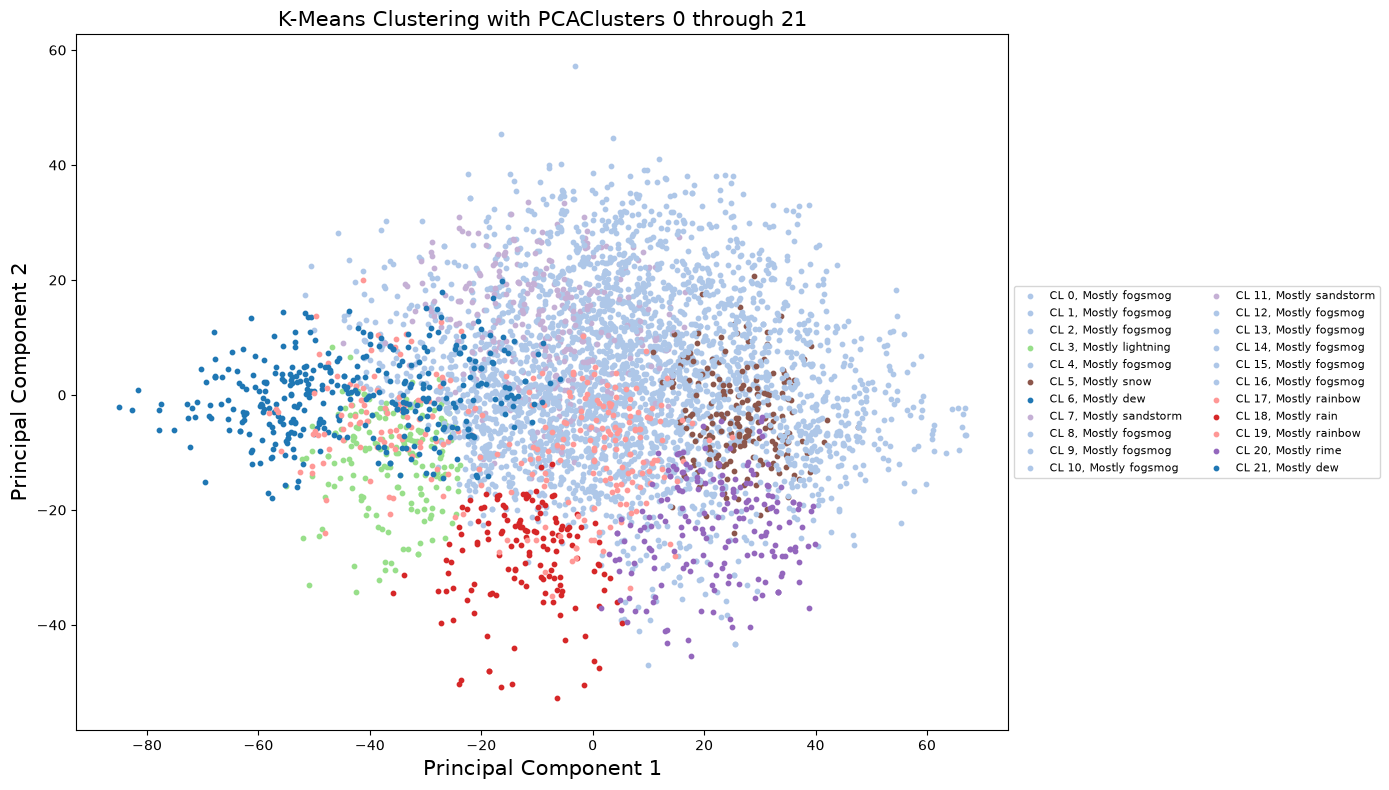

In [9]:
from sklearn.decomposition import PCA

# PCA reduces dimensionality and will help visualize our clusters
pca = PCA(n_components=2, random_state=42)
X_train_pca = pca.fit_transform(X)
X_test_pca = pca.transform(X_test.reshape(len(X_test), -1).astype(np.float32) / 255.)

plt.figure(figsize=(14, 8))
for i in range(n_groups):
    plt.scatter(X_train_pca[kmeans_labs == i, 0],
                X_train_pca[kmeans_labs == i, 1],
                color=class_colors[y_rep[i]], s=10,
                label=f"CL {i}, Mostly {y_rep[i]}")
plt.title(f"K-Means Clustering with PCA"
          f"Clusters 0 through {n_groups - 1}", fontsize=15)
plt.xlabel("Principal Component 1", fontsize=15)
plt.ylabel("Principal Component 2", fontsize=15)
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fontsize=8, ncol=2)
plt.tight_layout()
plt.show()

There appears to be heavy overlap, suggesting clusters are not well seperated here. We can measure cluster quality more quantitatively by producing a silhouette score - 

In [10]:
from sklearn.metrics import silhouette_score

print("Silhouette Score:", silhouette_score(X, kmeans_labs))
# closer to 0 means overlap, while 1 means well-seperated

Silhouette Score: 0.05108233913779259


Our silhouette score confirms our suspicions and confirms cluster overlap. To find out what share of images belong to each weather class within our clusters we plot our clusters - 

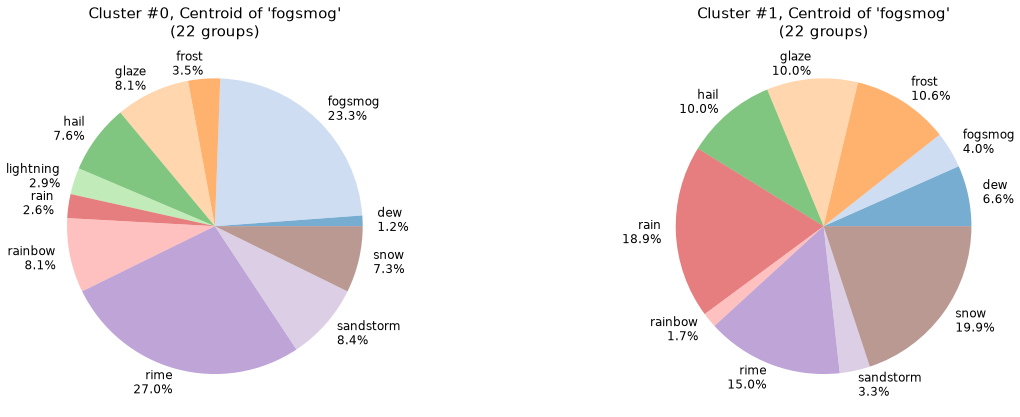

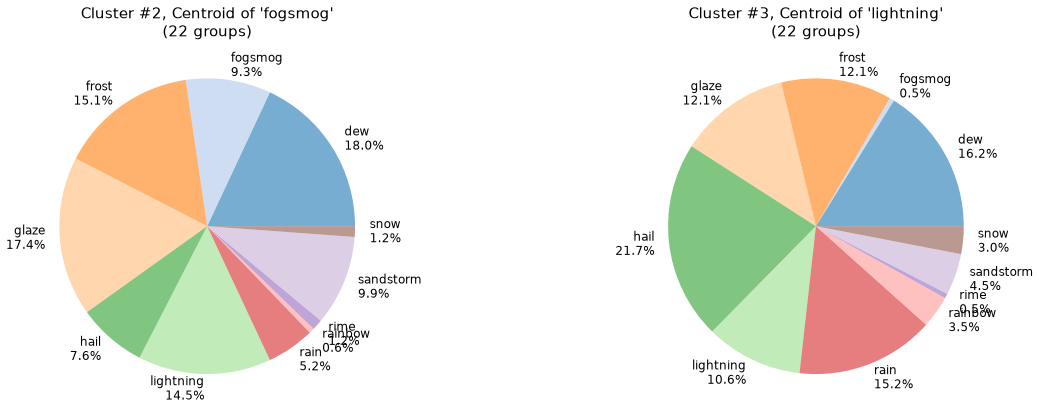

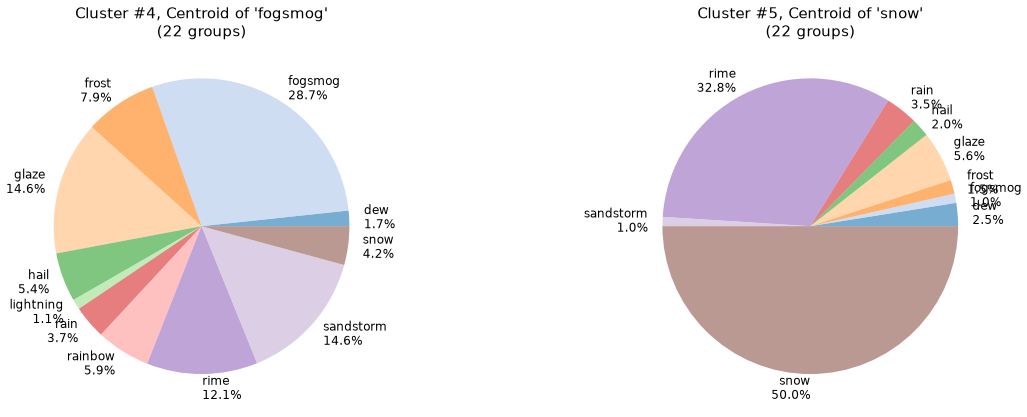

In [11]:
def plot_cluster_results(c1, c2):
    df = pd.DataFrame({'weather_label': y_train, 'kmeans_lab': kmeans_labs})
    fig, axs = plt.subplots(1, 2, figsize=(24, 8), dpi=60)

    for ax, c in zip(axs, (c1, c2)):
        counts = df[df['kmeans_lab'] == c]['weather_label'].value_counts().sort_index()
        pcts = counts / counts.sum() * 100
        labels = [f"{name}\n{p:.1f}%" for name, p in zip(counts.index, pcts)]

        ax.pie(counts, labels=labels,
               colors=[class_colors[k] for k in counts.index],
               wedgeprops={"alpha": 0.6}, textprops={'fontsize': 14},
               labeldistance=1.1)
        ax.set_title(f"Cluster #{c}, Centroid of '{y_rep[c]}'\n({n_groups} groups)",
                     fontsize=18)
    plt.show()

plot_cluster_results(0, 1)
plot_cluster_results(2, 3)
plot_cluster_results(4, 5)

We can also check to see exactly which images were captured in each cluster to get a better sense of the groupings - 

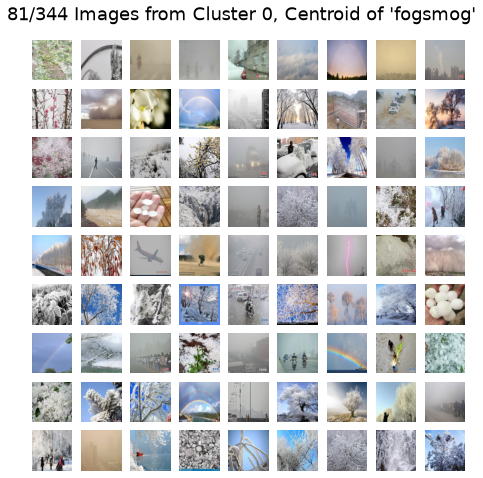

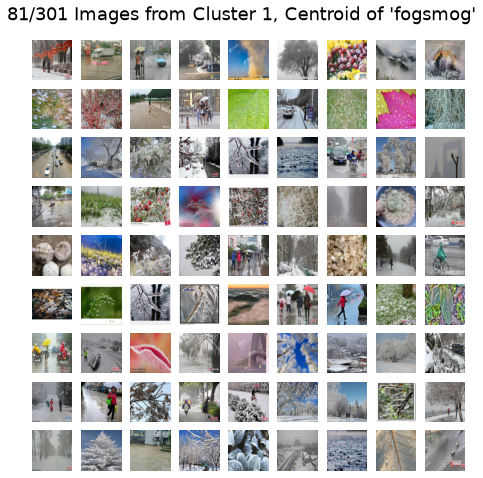

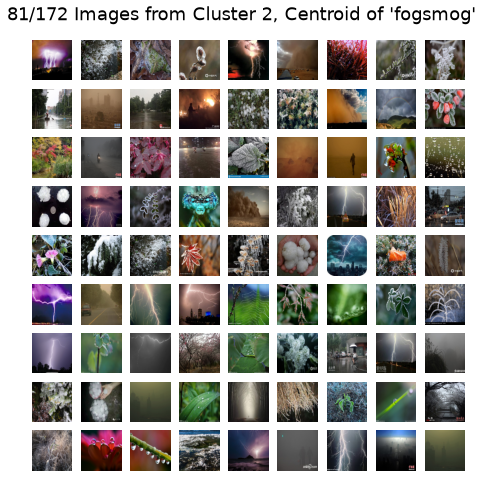

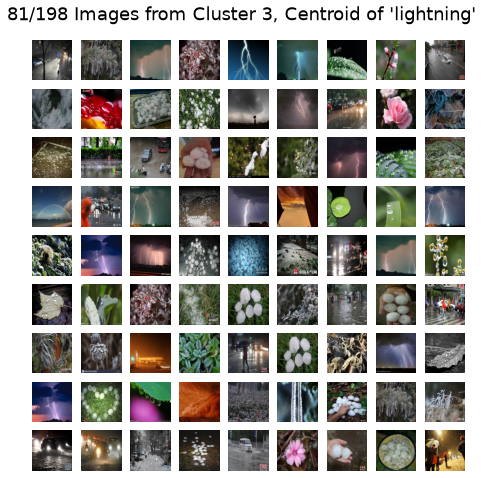

In [12]:
# using plot_cluster_images function 
def plot_cluster_images(cluster_num, num_images=81):
    idx = np.where(kmeans_labs == cluster_num)[0]
    n = min(num_images, len(idx))
    fig, ax = plt.subplots(9, 9, figsize=(8, 8), dpi=70)
    ax = ax.flatten()
    fig.suptitle(f"{n}/{len(idx)} Images from Cluster {cluster_num}, "
                 f"Centroid of '{y_rep[cluster_num]}'", fontsize=19, y=0.94)
    for i in range(len(ax)):
        ax[i].axis('off')
        if i < n:
            ax[i].imshow(X_train[idx[i]])
    plt.show()

plot_cluster_images(0)
plot_cluster_images(1)
plot_cluster_images(2)
plot_cluster_images(3)

To check the share of test images correctly classified, we train three different Naive-Bayes classifiers to compare accuracy between different models and methods

In [13]:
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score

X_train_flat = X
X_test_flat = X_test.reshape(len(X_test), -1).astype(np.float32) / 255.
X_rep_flat = X_rep.reshape(len(X_rep), -1).astype(np.float32) / 255.

np.random.seed(123)

# original data
nb = GaussianNB().fit(X_train_flat, y_train)
print(f"Naive Bayes with original data accuracy: "
      f"{accuracy_score(y_test, nb.predict(X_test_flat)):.2f}")

# centroid images only
nb = GaussianNB().fit(X_rep_flat, y_rep)
print(f"Naive Bayes with training K-means accuracy: ({n_groups} clusters): "
      f"{accuracy_score(y_test, nb.predict(X_test_flat)):.2f}")

# with PCA
nb = GaussianNB().fit(X_train_pca, y_train)
y_pred_pca = nb.predict(X_test_pca)
print(f"Naive Bayes with PCA accuracy: "
      f"{accuracy_score(y_test, y_pred_pca):.2f}")

# displaying predicted class distribution for PCA
display(pd.Series(y_pred_pca).value_counts())

Naive Bayes with original data accuracy: 0.48
Naive Bayes with training K-means accuracy: (22 clusters): 0.12
Naive Bayes with PCA accuracy: 0.32


rime         692
dew          386
fogsmog      353
hail         240
sandstorm    228
frost         85
rain          33
glaze         30
lightning     12
Name: count, dtype: int64

Our models were not as accurate as we would have hoped for, potentially due to too much noise in our image data (unconstrained images) and could perhaps be improved with more advanced cleaning methods. 

***Deep Neural Net***

For our first supervised machine learning method we will be implementing a deep neural net, similarly encoding and rescaling data as we did before our K-means clustering.

0 = dew
1 = fogsmog
2 = frost
3 = glaze
4 = hail
5 = lightning
6 = rain
7 = rainbow
8 = rime
9 = sandstorm
10 = snow
train_images shape: (4803, 100, 100, 3)


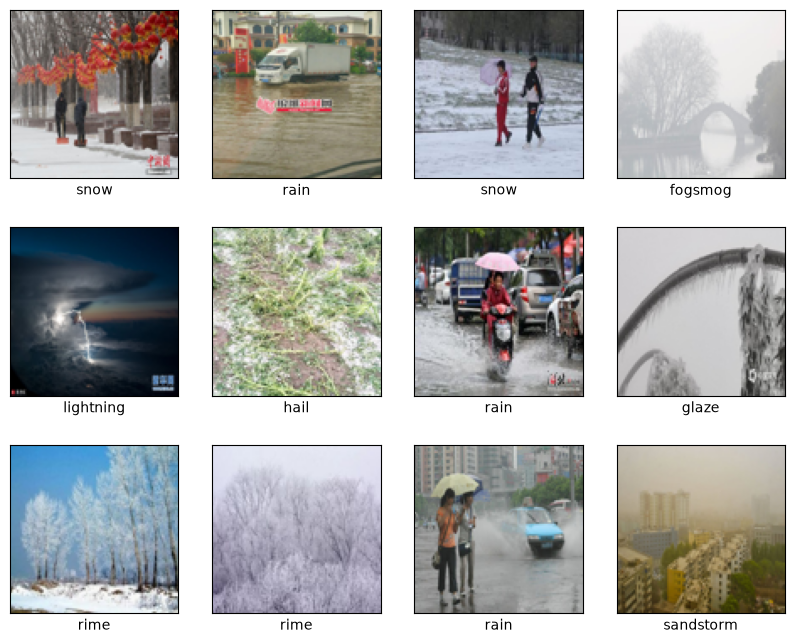

In [14]:
import random

# printing class names and encoded labels
class_names = list(label_encoder.classes_)
num_classes = len(class_names)
for i, name in enumerate(class_names):
    print(i, "=", name)

# encoding both train and test sets
train_images, train_labels = X_train, y_train_encoded
test_images, test_labels = X_test, y_test_encoded

print('train_images shape:', train_images.shape)

# need to scale pixels for our train and test images
train_images = train_images.astype('float32') / 255
test_images = test_images.astype('float32') / 255

# printing random training images to double-check
plt.figure(figsize=(10, 8))
for i in range(12):
    plt.subplot(3, 4, i + 1)
    plt.xticks([]); plt.yticks([])
    plt.grid(False)
    plt.imshow(train_images[i])
    plt.xlabel(class_names[train_labels[i]])
plt.show()

First we configure our model layers before we complile our model

In [16]:
# block must be run twice
# setting numpy and tensorflow seeds
random.seed(42)
np.random.seed(123)
tf.random.set_seed(1234)
# structure of model
mynet = tf.keras.Sequential([
    layers.Flatten(input_shape=(100, 100, 3), name='input_layer'),   # image -> vector of 30,000
    layers.Dense(units=128, activation='relu', name='hidden1'),
    layers.Dense(units=512, activation='tanh', name='hidden2'),
    layers.Dense(units=num_classes, activation='softmax', name='output_layer')  # one probability per class
], name='mynet')

# compiling
mynet.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',   # labels are integers, as in HW4
              metrics=['accuracy'])
# printing summary of compiled model and parameters
mynet.summary()

Model: "mynet"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (Flatten)           │ (None, 30000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden1 (Dense)                 │ (None, 128)            │     3,840,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ hidden2 (Dense)                 │ (None, 512)            │        66,048 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 11)             │         5,643 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,911,819 (14.92 MB)

 Trainable params: 3,911,819 (14.92 MB)

 Non-trainable params: 0 (0.00 B)

Now we fit our mynet model and can check the accuracy and value of loss function as our model improves with continued training through each epoch - 

In [17]:
mynet_history = mynet.fit(x=train_images, y=train_labels,
                          epochs=10, batch_size=500)

Epoch 1/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - accuracy: 0.1801 - loss: 2.6231
Epoch 2/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.3629 - loss: 2.0462
Epoch 3/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4070 - loss: 1.8574
Epoch 4/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4453 - loss: 1.7463
Epoch 5/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4707 - loss: 1.6643
Epoch 6/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4837 - loss: 1.6172
Epoch 7/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5003 - loss: 1.5808
Epoch 8/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.4961 - loss: 1.5479
Epoch 9/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.5032 - loss: 1.5221
Epoch 10/10
10/10 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.5109 - loss: 1.5088


In [18]:
test_loss, test_acc = mynet.evaluate(test_images, test_labels, verbose=2)
print("\nTest accuracy:", test_acc)

65/65 - 0s - 4ms/step - accuracy: 0.5036 - loss: 1.5370

Test accuracy: 0.5036425590515137


In [19]:
predictions = mynet.predict(test_images)
print('Shape of predictions array:', predictions.shape)   # (n_test, num_classes)

# Checking the first image plus predicted class
print(predictions[0])
print('Sum of probabilities:', np.sum(predictions[0]))
print('predicted:', class_names[np.argmax(predictions[0])],
      '| true:', class_names[test_labels[0]])

65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Shape of predictions array: (2059, 11)
[0.01393069 0.28603706 0.0505585  0.17788485 0.0132171  0.00635393
 0.03242708 0.03007086 0.27034056 0.02907934 0.09010003]
Sum of probabilities: 1.0
predicted: fogsmog | true: rime


We can use various plotting functions to further assess which classes were correctly predicted and which classes get mistaken for others - 

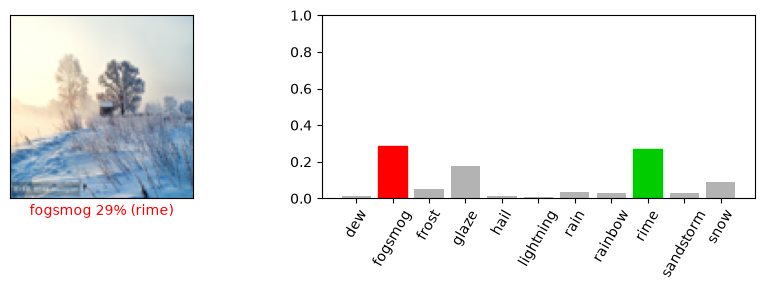

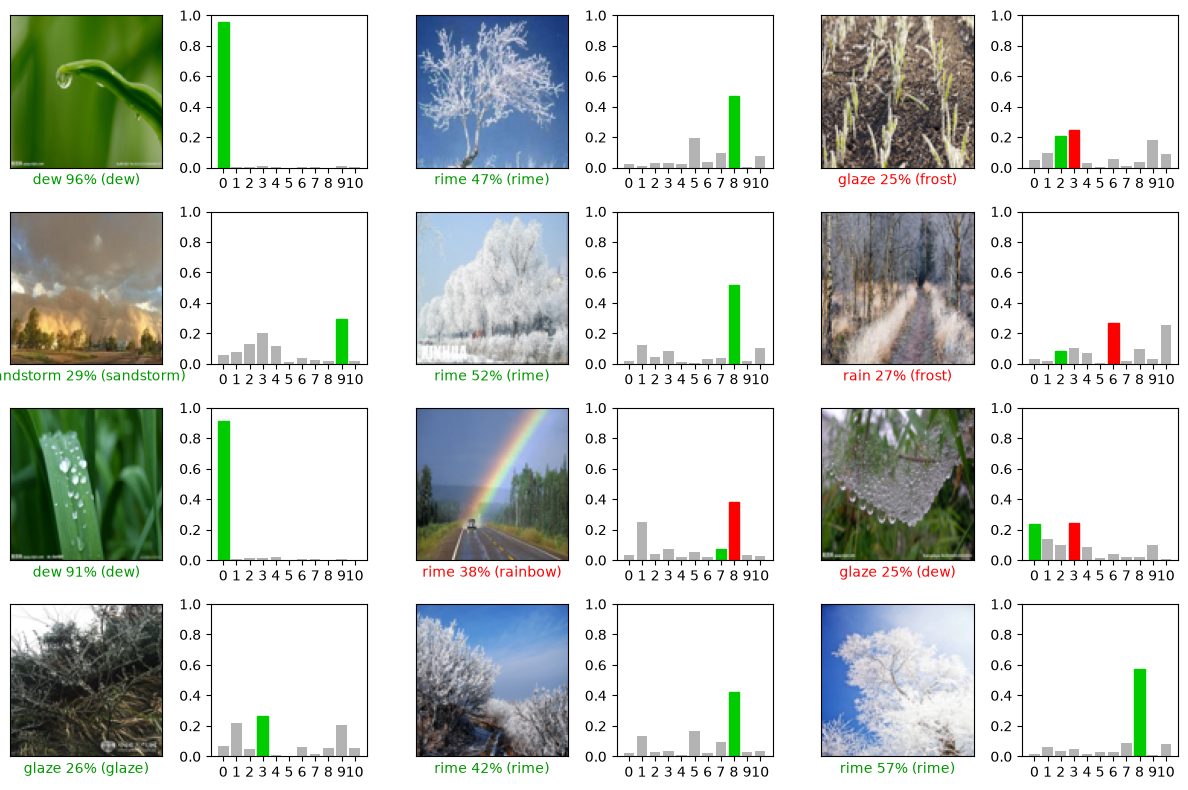

In [20]:

def plot_image(i, predictions_array, true_label, img):
    true_label, img = true_label[i], img[i]
    plt.grid(False)
    plt.xticks([]); plt.yticks([])
    plt.imshow(img)

    predicted_label = np.argmax(predictions_array)
    color = (0, 0.6, 0) if predicted_label == true_label else 'red'
    plt.xlabel("{} {:2.0f}% ({})".format(class_names[predicted_label],
                                         100 * np.max(predictions_array),
                                         class_names[true_label]),
               color=color)

def plot_value_array(i, predictions_array, true_label):
    true_label = true_label[i]
    plt.grid(False)
    plt.xticks(range(num_classes))
    plt.yticks([])
    thisplot = plt.bar(range(num_classes), predictions_array, color=(0.7, 0.7, 0.7))
    plt.ylim([0, 1])
    predicted_label = np.argmax(predictions_array)
    thisplot[predicted_label].set_color('red')
    thisplot[true_label].set_color((0, 0.8, 0))

# first checking a single image
i = 0
plt.figure(figsize=(9, 3))
plt.subplot(1, 2, 1)
plot_image(i, predictions[i], test_labels, test_images)
plt.subplot(1, 2, 2)
plot_value_array(i, predictions[i], test_labels)
plt.xticks(range(num_classes), class_names, rotation=60)
plt.yticks(0.2 * np.arange(6))
plt.tight_layout()
plt.show()

# outputting 12 random test imges together
li = random.sample(range(len(test_images)), 12)
num_rows, num_cols = 4, 3
plt.figure(figsize=(2 * 2 * num_cols, 2 * num_rows))
for k, idx in enumerate(li):
    plt.subplot(num_rows, 2 * num_cols, 2 * k + 1)
    plot_image(idx, predictions[idx], test_labels, test_images)
    plt.subplot(num_rows, 2 * num_cols, 2 * k + 2)
    plot_value_array(idx, predictions[idx], test_labels)
    plt.yticks(0.2 * np.arange(6))
plt.tight_layout()
plt.show()

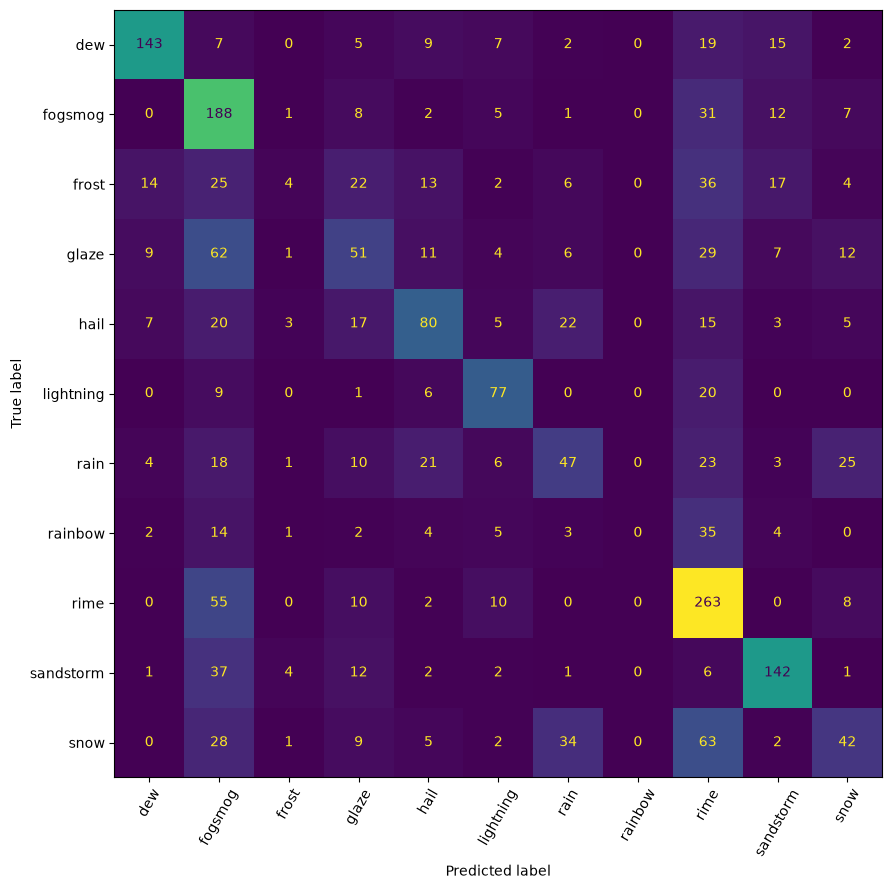

In [21]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

y_pred = np.argmax(predictions, axis=1)
cm = confusion_matrix(test_labels, y_pred)

fig, ax = plt.subplots(figsize=(9, 9))
ConfusionMatrixDisplay(cm, display_labels=class_names).plot(ax=ax, xticks_rotation=60, colorbar=False)
plt.tight_layout()
plt.show()

***Convolutional Autoencoder***

For our second method, we will be building a convolutional autoencoder to correctly classify weather data. A convolutional neural network could perform better in capturing the relationship between pixels compared to our previous model. 

In [22]:
from tensorflow.keras import Model

np.random.seed(123)
tf.random.set_seed(1234)

inputs = layers.Input(shape=(100, 100, 3))

# encoding layers
x = layers.Conv2D(32, 3, activation='relu', padding='same')(inputs)
x = layers.MaxPooling2D(2)(x)                       # 50x50
x = layers.Conv2D(64, 3, activation='relu', padding='same')(x)
x = layers.MaxPooling2D(2)(x)                       # 25x25
x = layers.Flatten()(x)
latent = layers.Dense(64, activation='relu', name='latent')(x)   # the learned features

# decoding layers (runs process in reverse)
x = layers.Dense(25 * 25 * 64, activation='relu')(latent)
x = layers.Reshape((25, 25, 64))(x)
x = layers.UpSampling2D(2)(x)                       # 50x50
x = layers.Conv2DTranspose(32, 3, activation='relu', padding='same')(x)
x = layers.UpSampling2D(2)(x)                       # 100x100
outputs = layers.Conv2D(3, 3, activation='sigmoid', padding='same')(x)

autoencoder = Model(inputs, outputs, name='autoencoder')
autoencoder.compile(optimizer='adam', loss='mse')
autoencoder.summary()

ae_history = autoencoder.fit(train_images, train_images,
                             epochs=15, batch_size=64, validation_split=0.1)

Model: "autoencoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_2 (InputLayer)      │ (None, 100, 100, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 100, 100, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 50, 50, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 50, 50, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 40000)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 64)             │     2,560,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 40000)          │     2,600,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 25, 25, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 50, 50, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 50, 50, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 100, 100, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 100, 100, 3)    │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,198,787 (19.83 MB)

 Trainable params: 5,198,787 (19.83 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 8s 109ms/step - loss: 0.0485 - val_loss: 0.0353
Epoch 2/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 98ms/step - loss: 0.0271 - val_loss: 0.0233
Epoch 3/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - loss: 0.0221 - val_loss: 0.0214
Epoch 4/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 97ms/step - loss: 0.0205 - val_loss: 0.0203
Epoch 5/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - loss: 0.0193 - val_loss: 0.0189
Epoch 6/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 97ms/step - loss: 0.0183 - val_loss: 0.0178
Epoch 7/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 97ms/step - loss: 0.0175 - val_loss: 0.0170
Epoch 8/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - loss: 0.0169 - val_loss: 0.0165
Epoch 9/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 97ms/step - loss: 0.0163 - val_loss: 0.0170
Epoch 10/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - loss: 0.0160 - val_loss: 0.0172
Epoch 11/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 96ms/step - loss: 0.0162 - val_loss: 0.0175
Epoch 12/15
68/68 ━━━━━━━━━━━━━━━━━━━━ 7s 97ms/step - loss: 0.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 106ms/step


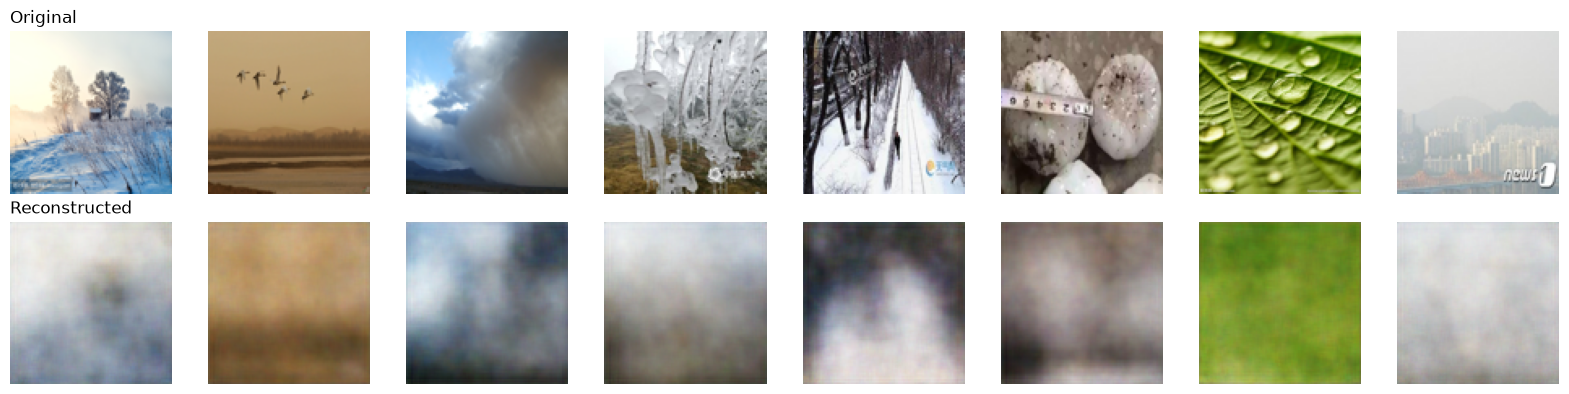

In [23]:
# plotting first 8 test images
recon = autoencoder.predict(test_images[:8])

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i in range(8):
    axes[0, i].imshow(test_images[i]); axes[0, i].axis('off')
    axes[1, i].imshow(recon[i]);       axes[1, i].axis('off')
axes[0, 0].set_title("Original", loc='left')
axes[1, 0].set_title("Reconstructed", loc='left')
plt.tight_layout(); plt.show() # display reconstructed images

In [24]:
# predicting on our train and test images
encoder = Model(inputs, latent)
Z_train = encoder.predict(train_images)
Z_test = encoder.predict(test_images)
print(Z_train.shape)

151/151 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step
65/65 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step
(4803, 64)


We can perform k-means analysis and also produce an adjusted random index that tells us how well each cluster matches the true label and a normalized mutual information score that indicates how much we know about the true weather classes given a cluster. In all cases, scores closer to 1 represent better accuracy, more distinct grouping, or more information within each cluster.  

In [25]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score, normalized_mutual_info_score

km_z = KMeans(n_clusters=num_classes, n_init=50, random_state=42).fit(Z_train)
print("Embedding k-means silhouette:", silhouette_score(Z_train, km_z.labels_))
print("Adjusted random index:", adjusted_rand_score(train_labels, km_z.labels_))
print("Normalized mutual information:", normalized_mutual_info_score(train_labels, km_z.labels_))

Embedding k-means silhouette: 0.09940072149038315
Adjusted random index: 0.09388259534886538
Normalized mutual information: 0.20473429655001524


In [26]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

clf = LogisticRegression(max_iter=2000).fit(Z_train, train_labels)
print("Accuracy on autoencoder embeddings:", accuracy_score(test_labels, clf.predict(Z_test)))

Accuracy on autoencoder embeddings: 0.5468674113647402


Our convolutional autoencoder was slightly more accurate in predicting weather classes when compared to our earlier deep neural net model. 

***Conclusion***

The models weren't as accurate as I would have hoped for, potentially due to our image data being unconstrained and difficult to distinguish. Cleaner images on distinct backgrounds or perhaps more advanced preprocessing techniques could significantly increase model performance for these machine learning methods. Despite this, our convolutional autoencoder had the most impressive accuracy with a moderate 54%, slightly beating the deep neural net and outperforming our k-means analysis. The results are promising initially and show that there is a lot of room to apply new methods in the future to build better models. 

References: 

Chollet, F. (2021). Deep learning with Python (2nd ed.). Manning Publications.

GeeksforGeeks. (n.d.). Implement convolutional autoencoder in PyTorch with CUDA. https://www.geeksforgeeks.org/machine-learning/implement-convolutional-autoencoder-in-pytorch-with-cuda/

Mahzabeen, S. (2026). HW4. DAT 402, Arizona State University.

Mahzabeen, S. (2026). Fruits360 Project2_example.html. DAT 402, Arizona State University.

Om Pramod. (n.d.). Autoencoders explained. Medium. https://medium.com/@ompramod/autoencoders-explained-1fa7f4c32f12

Samara, M. (n.d.). Clustering [Lecture notes]. Arizona State University. https://math.la.asu.edu/~samara/MLearn-lectures/k-means-clustering.html

TensorFlow. (n.d.). Keras tutorials. https://www.tensorflow.org/tutorials/keras

Udacity. (n.d.). Convolutional autoencoder solution [Jupyter notebook]. GitHub. https://github.com/udacity/deep-learning-v2-pytorch/blob/master/autoencoder/convolutional-autoencoder/Convolutional_Autoencoder_Solution.ipynb